In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, GRU
from tensorflow.random import set_seed
from sklearn.model_selection import train_test_split

In [2]:
dataset = pd.read_csv(
                    "D:\Artificial Intelligence\Deep Learning\Data\Mastercard_stock_history.csv",
                    index_col="Date",
                    parse_dates=["Date"]
                      )
dataset = dataset.drop(["Dividends", "Stock Splits"], axis=1)
dataset

<>:2: SyntaxWarning: invalid escape sequence '\A'
<>:2: SyntaxWarning: invalid escape sequence '\A'
C:\Users\HASEEB\AppData\Local\Temp\ipykernel_16376\643872254.py:2: SyntaxWarning: invalid escape sequence '\A'
  "D:\Artificial Intelligence\Deep Learning\Data\Mastercard_stock_history.csv",


,Open,High,Low,Close,Volume
Date,,,,,
2006-05-25 00:00:00-04:00,3.677800,4.202548,3.668674,4.197985,395343000
2006-05-26 00:00:00-04:00,4.225363,4.265517,4.025502,4.100336,103044000
2006-05-30 00:00:00-04:00,4.103990,4.104902,3.910517,4.015467,49898000
2006-05-31 00:00:00-04:00,4.047406,4.139579,4.047406,4.101250,30002000
2006-06-01 00:00:00-04:00,4.100334,4.389630,4.097596,4.335786,62344000
...,...,...,...,...,...
2025-03-12 00:00:00-04:00,530.510010,532.710022,519.260010,524.640015,2810800
2025-03-13 00:00:00-04:00,524.500000,528.530029,517.710022,519.830017,2375800
2025-03-14 00:00:00-04:00,522.599976,528.409973,520.950012,527.640015,2369500


In [3]:
data = dataset["High"].values
data = data.reshape(-1,1)

In [4]:
data


array([[  4.2025483 ],
       [  4.26551693],
       [  4.10490213],
       ...,
       [528.40997314],
       [533.47998047],
       [532.59002686]], shape=(4733, 1))

In [5]:
from tensorflow.keras.layers import Dense, SimpleRNN

sc = MinMaxScaler()
data = sc.fit_transform(data)
data

array([[3.07779089e-04],
       [4.16682654e-04],
       [1.38901078e-04],
       ...,
       [9.06918877e-01],
       [9.15687400e-01],
       [9.14148235e-01]], shape=(4733, 1))

In [6]:
X = []
y = []
n_steps = 60
for i in range(n_steps, len(data)):
    
    X.append(data[i-n_steps:i])
    y.append(data[i])

X = np.array(X)
y = np.array(y)


In [7]:
X

array([[[3.07779089e-04],
        [4.16682654e-04],
        [1.38901078e-04],
        ...,
        [1.78826128e-03],
        [1.60043914e-03],
        [1.50731421e-03]],

       [[4.16682654e-04],
        [1.38901078e-04],
        [1.98875126e-04],
        ...,
        [1.60043914e-03],
        [1.50731421e-03],
        [1.80720222e-03]],

       [[1.38901078e-04],
        [1.98875126e-04],
        [6.31334123e-04],
        ...,
        [1.50731421e-03],
        [1.80720222e-03],
        [1.79931114e-03]],

       ...,

       [[9.16401938e-01],
        [9.16954529e-01],
        [9.11393807e-01],
        ...,
        [9.23591178e-01],
        [9.14355765e-01],
        [9.07126513e-01]],

       [[9.16954529e-01],
        [9.11393807e-01],
        [9.20632975e-01],
        ...,
        [9.14355765e-01],
        [9.07126513e-01],
        [9.06918877e-01]],

       [[9.11393807e-01],
        [9.20632975e-01],
        [9.06972794e-01],
        ...,
        [9.07126513e-01],
        [9.0691

In [8]:
y

array([[0.0018072 ],
       [0.00179931],
       [0.00183877],
       ...,
       [0.90691888],
       [0.9156874 ],
       [0.91414823]], shape=(4673, 1))

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)
X_train

array([[[3.07779089e-04],
        [4.16682654e-04],
        [1.38901078e-04],
        ...,
        [1.78826128e-03],
        [1.60043914e-03],
        [1.50731421e-03]],

       [[4.16682654e-04],
        [1.38901078e-04],
        [1.98875126e-04],
        ...,
        [1.60043914e-03],
        [1.50731421e-03],
        [1.80720222e-03]],

       [[1.38901078e-04],
        [1.98875126e-04],
        [6.31334123e-04],
        ...,
        [1.50731421e-03],
        [1.80720222e-03],
        [1.79931114e-03]],

       ...,

       [[6.10669705e-01],
        [6.09351165e-01],
        [6.04161289e-01],
        ...,
        [6.19916339e-01],
        [6.30189869e-01],
        [6.34099694e-01]],

       [[6.09351165e-01],
        [6.04161289e-01],
        [6.07373281e-01],
        ...,
        [6.30189869e-01],
        [6.34099694e-01],
        [6.34032081e-01]],

       [[6.04161289e-01],
        [6.07373281e-01],
        [6.19409634e-01],
        ...,
        [6.34099694e-01],
        [6.3403

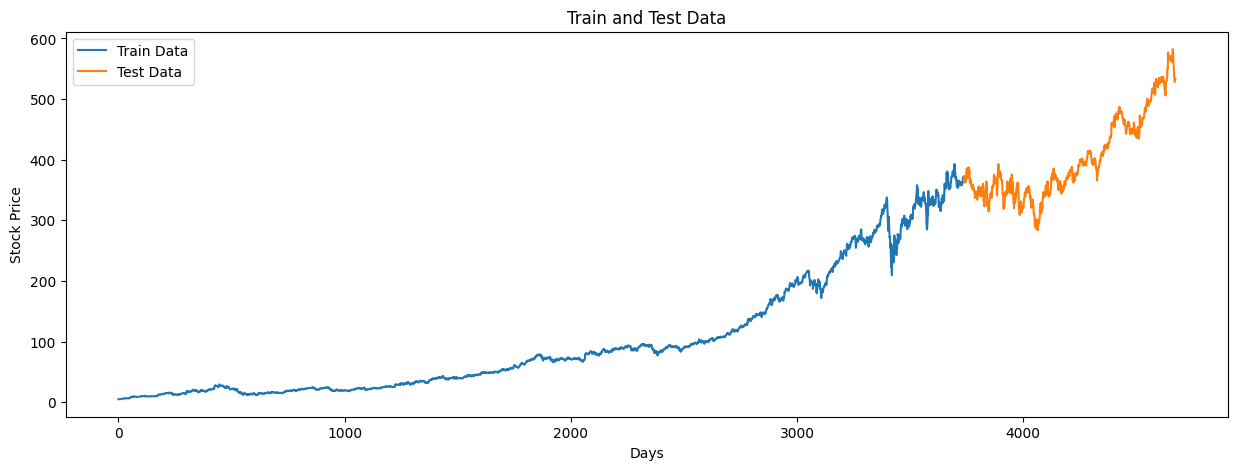

In [10]:
train_plot = sc.inverse_transform(y_train)
test_plot = sc.inverse_transform(y_test)
plt.figure(figsize=(15,5))
plt.plot(range(len(train_plot)), train_plot, label="Train Data")
plt.plot(
    range(len(train_plot), len(train_plot)+len(test_plot)),
    test_plot,
    label="Test Data"
)
plt.title("Train and Test Data")
plt.xlabel("Days")
plt.ylabel("Stock Price")
plt.legend()

In [11]:
model = Sequential()
model.add(SimpleRNN(50, activation="tanh", input_shape=(60, 1)))
model.add(Dense(1))
model.compile(optimizer="adam", loss="mse")
model.summary()

c:\Users\HASEEB\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.fit(X_train, y_train, epochs=20, batch_size=32)

Epoch 1/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 7.8272e-04
Epoch 2/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 8.2710e-05
Epoch 3/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 6.5114e-05
Epoch 4/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 6.5012e-05
Epoch 5/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 5.6335e-05
Epoch 6/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 6.5158e-05
Epoch 7/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 5.2411e-05
Epoch 8/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 4.3644e-05
Epoch 9/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.8714e-05
Epoch 10/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.2526e-05
Epoch 11/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 3.9298e-05
Epoch 12/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.0847e-05
Epoch 13/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 3.2940e-05
Epoch 14/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 3.2465e-05
E

30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step


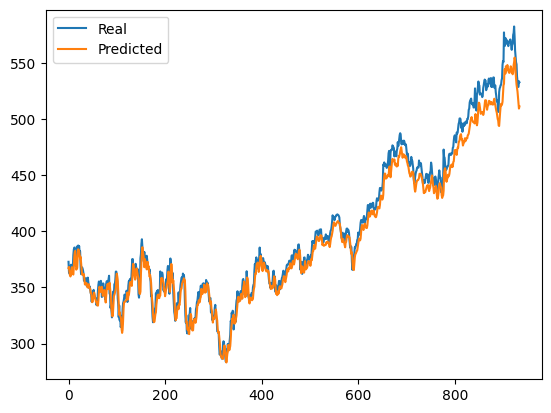

RMSE: 10.731799708440132


In [13]:
pred = model.predict(X_test)
pred = sc.inverse_transform(pred)
real = sc.inverse_transform(y_test)
plt.plot(real, label="Real")
plt.plot(pred, label="Predicted")
plt.legend()
plt.show()
rmse = np.sqrt(mean_squared_error(real, pred))
print("RMSE:", rmse)

In [14]:
model = Sequential()
model.add(LSTM(125, activation="tanh", input_shape=(60,1)))
model.add(Dense(1))

model.compile(optimizer="RMSprop", loss="mse")
model.summary()

c:\Users\HASEEB\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 125)            │        63,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           126 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 63,626 (248.54 KB)

 Trainable params: 63,626 (248.54 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
model.fit(X_train, y_train, epochs=50, batch_size=32)


Epoch 1/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0016
Epoch 2/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - loss: 2.6097e-04
Epoch 3/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 2.1819e-04
Epoch 4/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - loss: 1.9099e-04
Epoch 5/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - loss: 1.4318e-04
Epoch 6/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - loss: 1.2765e-04
Epoch 7/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - loss: 1.2465e-04
Epoch 8/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - loss: 1.1013e-04
Epoch 9/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - loss: 1.1476e-04
Epoch 10/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 9s 78ms/step - loss: 9.9256e-05
Epoch 11/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - loss: 9.4861e-05
Epoch 12/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - loss: 9.3083e-05
Epoch 13/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 6s 52ms/step - loss: 8.4248e-05
Epoch 14/50
117/117 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - loss: 8.

30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step


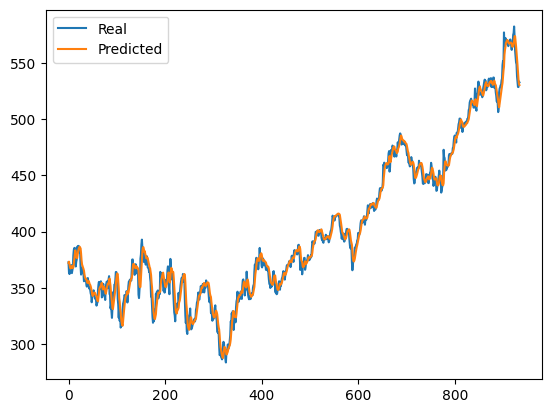

RMSE: 7.206335587898834


In [16]:
pred = model.predict(X_test)
pred = sc.inverse_transform(pred)
real = sc.inverse_transform(y_test)
plt.plot(real, label="Real")
plt.plot(pred, label="Predicted")
plt.legend()
plt.show()
rmse = np.sqrt(mean_squared_error(real, pred))
print("RMSE:", rmse)

In [17]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

In [18]:
y_test

array([[0.63775555],
       [0.62162582],
       [0.61956088],
       [0.62132112],
       [0.62856505],
       [0.63321962],
       [0.6330672 ],
       [0.62101068],
       [0.62590792],
       [0.63029672],
       [0.64820773],
       [0.65666345],
       [0.65949313],
       [0.65976427],
       [0.63458385],
       [0.63119469],
       [0.63848114],
       [0.64180246],
       [0.66152661],
       [0.65879847],
       [0.66284826],
       [0.65683288],
       [0.66193324],
       [0.6522068 ],
       [0.65386736],
       [0.63131331],
       [0.61875708],
       [0.62333219],
       [0.6293308 ],
       [0.62763634],
       [0.62467084],
       [0.61994305],
       [0.60852205],
       [0.60899652],
       [0.60952191],
       [0.61062335],
       [0.61269068],
       [0.60330304],
       [0.600219  ],
       [0.60686147],
       [0.6134024 ],
       [0.60713262],
       [0.60001564],
       [0.59713487],
       [0.59974451],
       [0.59496607],
       [0.58959438],
       [0.587

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


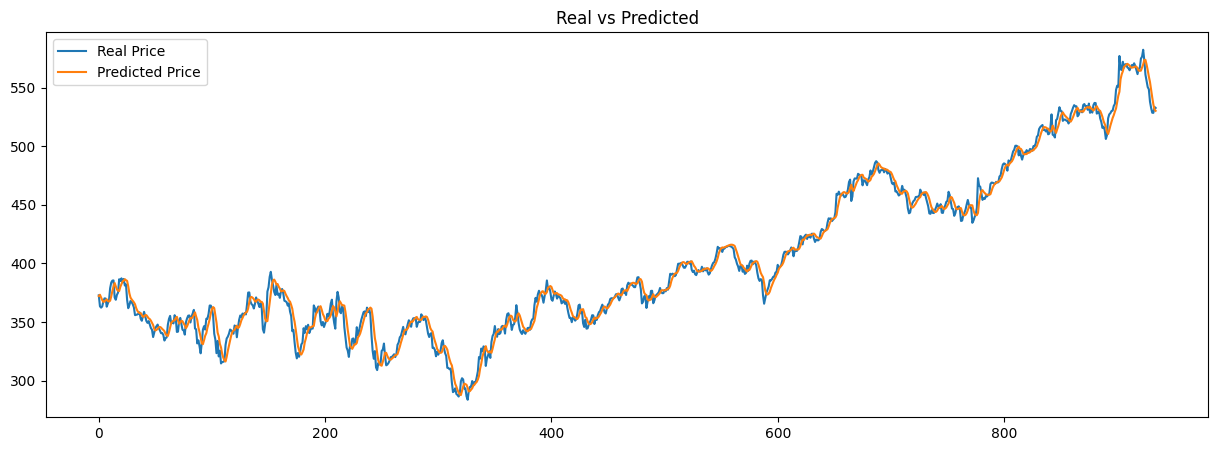

MSE  : 51.931272605417234
RMSE : 7.206335587898834
MAE  : 5.379377832680712
R2   : 0.9888823211571828
MAPE : 1.4035402583648655 %


In [19]:
pred = model.predict(X_test)
pred = sc.inverse_transform(pred)
real = sc.inverse_transform(y_test)
plt.figure(figsize=(15,5))
plt.plot(real, label="Real Price")
plt.plot(pred, label="Predicted Price")
plt.title("Real vs Predicted")
plt.legend()
plt.show()
mse = mean_squared_error(real, pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(real, pred)
r2 = r2_score(real, pred)
mape = np.mean(np.abs((real - pred) / real)) * 100
print("MSE  :", mse)
print("RMSE :", rmse)
print("MAE  :", mae)
print("R2   :", r2)
print("MAPE :", mape,"%")

In [20]:
pred

array([[372.1779 ],
       [373.26566],
       [370.98322],
       [368.71072],
       [367.22827],
       [367.44962],
       [368.5465 ],
       [369.4171 ],
       [367.87054],
       [367.56406],
       [368.15036],
       [371.94287],
       [376.44397],
       [380.36902],
       [383.27954],
       [380.64032],
       [377.7257 ],
       [376.67627],
       [376.45636],
       [379.96088],
       [382.1916 ],
       [384.6158 ],
       [385.26987],
       [386.57867],
       [385.6613 ],
       [385.13898],
       [380.48715],
       [374.53555],
       [370.85455],
       [369.32336],
       [368.0874 ],
       [366.82452],
       [365.17822],
       [361.96973],
       [359.74597],
       [358.31946],
       [357.6274 ],
       [357.6662 ],
       [356.11688],
       [354.46503],
       [354.53174],
       [355.9199 ],
       [355.93192],
       [354.6655 ],
       [353.17245],
       [352.5417 ],
       [351.2378 ],
       [349.30765],
       [347.4239 ],
       [344.06528],


In [21]:
# model.save("MASTER_CARD.model.h5")
# print("Model saved successfully!")

In [22]:
# from tensorflow import keras
# loaded_model = keras.models.load_model("D:/Artificial Intelligence/Deep Learning/Models/MASTER_CARD.weights.h5")
# print("Model loaded Successfully!")
from tensorflow import keras

loaded_model = keras.models.load_model(
    "D:/Artificial Intelligence/Deep Learning/Models/MASTER_CARD.weights.h5",
    compile=False
)

print("Model loaded successfully!")

Model loaded successfully!


30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step


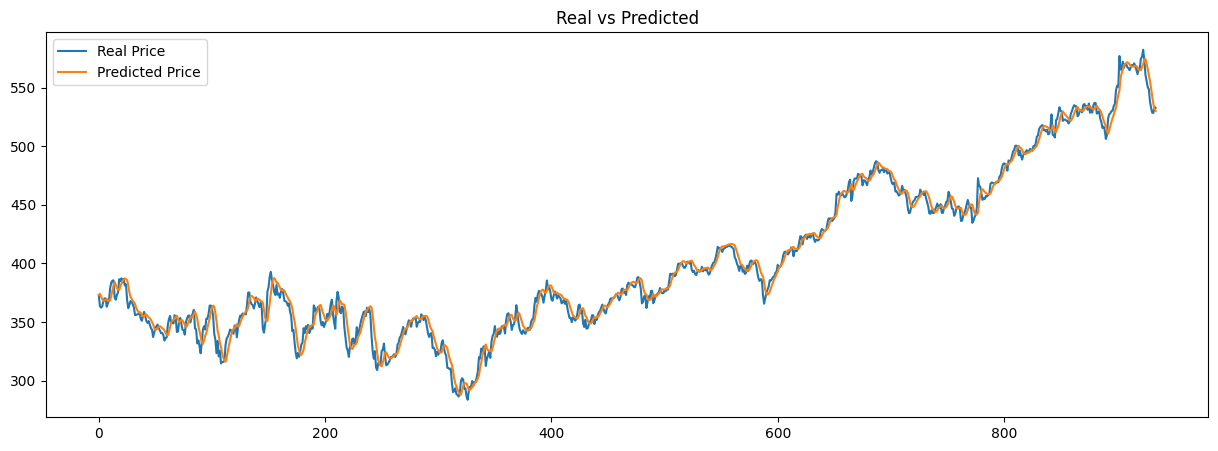

MSE  : 54.67256557987309
RMSE : 7.394089908830774
MAE  : 5.524833357372511
R2   : 0.9882954529104591
MAPE : 1.4436379475749852 %


In [23]:
pred = loaded_model.predict(X_test)
pred = sc.inverse_transform(pred)
real = sc.inverse_transform(y_test)
plt.figure(figsize=(15,5))
plt.plot(real, label="Real Price")
plt.plot(pred, label="Predicted Price")
plt.title("Real vs Predicted")
plt.legend()
plt.show()
mse = mean_squared_error(real, pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(real, pred)
r2 = r2_score(real, pred)
mape = np.mean(np.abs((real - pred) / real)) * 100
print("MSE  :", mse)
print("RMSE :", rmse)
print("MAE  :", mae)
print("R2   :", r2)
print("MAPE :", mape,"%")